# ARTI403 – Image Processing
## Lab 6: Frequency Domain

**Name:** Abdulsamad Mousa Tuhaishi
**ID:** 2240001093

## Task #1 Laplacian Filtering in the Frequency Domain

.

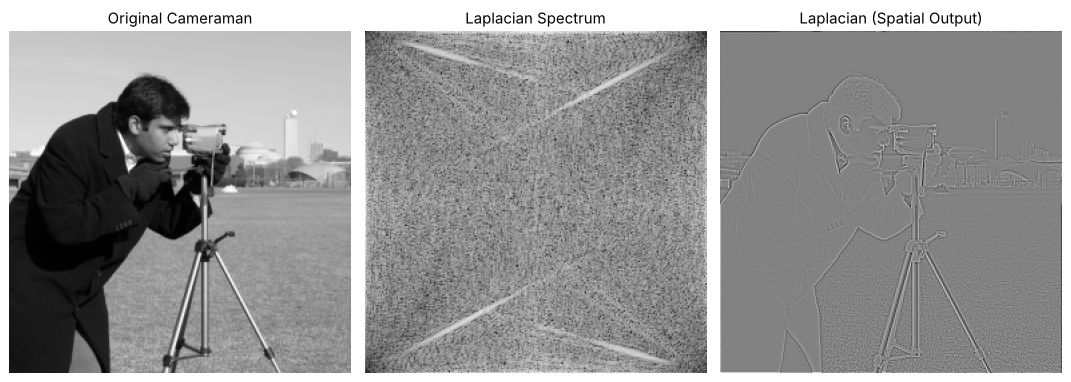

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, io
from skimage.transform import resize
from numpy.fft import fft2, ifft2, fftshift, ifftshift

# Load cameraman image (already grayscale)
image = data.camera()
image = resize(image, (256, 256))  # Resize for faster FFT

# Save the image used in this lab
io.imsave('cameraman.png', (image * 255).astype(np.uint8))

# Get image size
M, N = image.shape

# Generate frequency grid
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)

# Laplacian filter in frequency domain
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)

# Apply 2D FFT
F = np.fft.fft2(image)

# Apply Laplacian filter in frequency domain
F_lap = F * laplacian_filter

# Inverse FFT to get spatial result
laplacian_image = np.fft.ifft2(F_lap).real

# Plot results
plt.figure(figsize=(12, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(F_lap)), cmap='gray')
plt.title('Laplacian Spectrum')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap='gray')
plt.title('Laplacian (Spatial Output)')
plt.axis('off')

plt.tight_layout()
plt.savefig('task1_laplacian.png', dpi=100)
plt.show()

## Assessment Task #1: Sobel Filters in the Frequency Domain

Steps:

1. Load and resize the Cameraman image.
2. Define the Sobel kernels $S_x$ and $S_y$.
3. Zero-pad each 3×3 kernel to the image size, centre it, and apply `ifftshift` so its centre sits at (0, 0) before taking the FFT.
4. Multiply the image spectrum by each filter spectrum (convolution theorem: $f * h \Leftrightarrow F \cdot H$).
5. Inverse FFT to get $G_x$, $G_y$, then the gradient magnitude $\sqrt{G_x^2 + G_y^2}$.

In [2]:
# Load and resize image
image = data.camera()
image = resize(image, (256, 256))
M, N = image.shape

# Sobel filters
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [ 0,  0,  0],
                    [ 1,  2,  1]])

# Proper padding and centering of kernel in spatial domain
def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape)
    kh, kw = kernel.shape
    ph, pw = shape
    # Find center coordinates
    cy, cx = ph // 2, pw // 2
    # Insert kernel centered at the image center
    padded[cy - kh//2:cy - kh//2 + kh, cx - kw//2:cx - kw//2 + kw] = kernel
    return fft2(ifftshift(padded))  # Shift before FFT to place (0,0) at top-left

# Compute FFT of image
F = fft2(image)

# FFT of centered Sobel filters
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)

# Multiply in the frequency domain
F_x = F * H_x
F_y = F * H_y

# Back to the spatial domain
G_x = np.real(ifft2(F_x))
G_y = np.real(ifft2(F_y))
G_mag = np.sqrt(G_x**2 + G_y**2)

print('Image shape        :', image.shape)
print('Gx range           : [%.3f, %.3f]' % (G_x.min(), G_x.max()))
print('Gy range           : [%.3f, %.3f]' % (G_y.min(), G_y.max()))
print('Magnitude range    : [%.3f, %.3f]' % (G_mag.min(), G_mag.max()))

Image shape        : (256, 256)
Gx range           : [-3.180, 3.303]
Gy range           : [-2.979, 2.665]
Magnitude range    : [0.000, 3.448]


### Filter spectra (magnitude of $H_x$ and $H_y$)

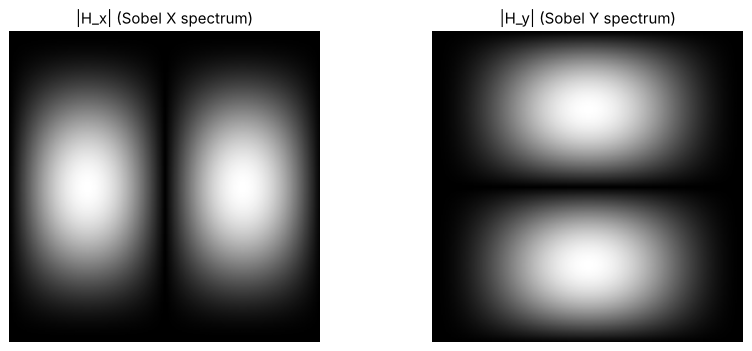

In [3]:
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(fftshift(H_x)), cmap='gray')
plt.title('|H_x| (Sobel X spectrum)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(np.abs(fftshift(H_y)), cmap='gray')
plt.title('|H_y| (Sobel Y spectrum)')
plt.axis('off')

plt.tight_layout()
plt.savefig('sobel_filter_spectra.png', dpi=100)
plt.show()

### Filtered spectra and spatial results

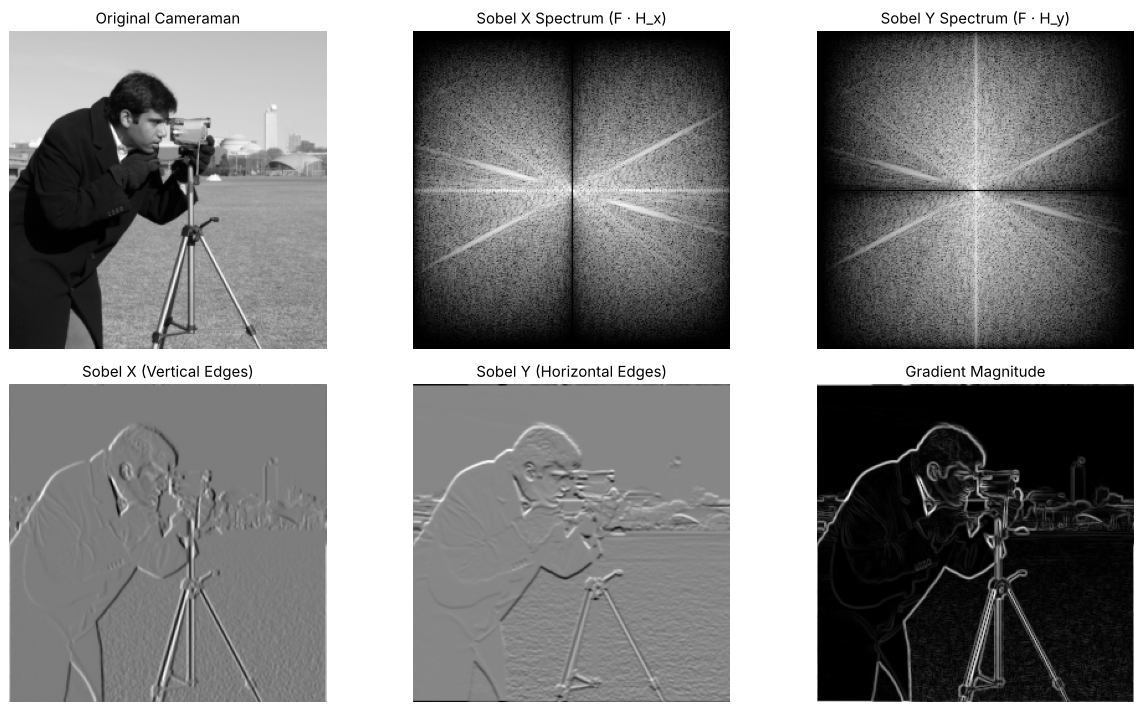

In [4]:
plt.figure(figsize=(14, 8))

plt.subplot(2, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Cameraman')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(np.log(1 + np.abs(fftshift(F_x))), cmap='gray')
plt.title('Sobel X Spectrum (F · H_x)')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(np.log(1 + np.abs(fftshift(F_y))), cmap='gray')
plt.title('Sobel Y Spectrum (F · H_y)')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(G_x, cmap='gray')
plt.title('Sobel X (Vertical Edges)')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(G_y, cmap='gray')
plt.title('Sobel Y (Horizontal Edges)')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(G_mag, cmap='gray')
plt.title('Gradient Magnitude')
plt.axis('off')

plt.tight_layout()
plt.savefig('sobel_frequency_results.png', dpi=100)
plt.show()

### Verification against spatial-domain convolution

Multiplying spectra is equivalent to **circular convolution** in the spatial domain, so the result should match
`scipy.ndimage.convolve` with `mode='wrap'`.

In [5]:
from scipy.ndimage import convolve

G_x_spatial = convolve(image, sobel_x, mode='wrap')
G_y_spatial = convolve(image, sobel_y, mode='wrap')

print('Max |Gx(freq) - Gx(spatial)| =', np.abs(G_x - G_x_spatial).max())
print('Max |Gy(freq) - Gy(spatial)| =', np.abs(G_y - G_y_spatial).max())
print('Results match:', np.allclose(G_x, G_x_spatial) and np.allclose(G_y, G_y_spatial))

Max |Gx(freq) - Gx(spatial)| = 1.4883927423881005e-15
Max |Gy(freq) - Gy(spatial)| = 2.8380076066980564e-15
Results match: True
